# Lecture 6 — Class Exercise
## Choropleth Maps

> **Push to:** `week06/lecture06_exercise.ipynb`

**Rules:**
1. Use `px.choropleth` or `px.choropleth_map` — choose deliberately and state your reason
2. Right colour scale for your data (sequential vs diverging) — state which and why
3. Insight title names a geographic finding — not just a topic
4. `featureidkey` must be correctly matched to your GeoJSON

---


In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import json
import numpy as np

In [ ]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import json


In [2]:
gm = px.data.gapminder()

gm_2007 = gm[gm['year'] == 2007].copy()

gm_2007.head()

,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
11,Afghanistan,Asia,2007,43.828,31889923,974.580338,AFG,4
23,Albania,Europe,2007,76.423,3600523,5937.029526,ALB,8
35,Algeria,Africa,2007,72.301,33333216,6223.367465,DZA,12
47,Angola,Africa,2007,42.731,12420476,4797.231267,AGO,24
59,Argentina,Americas,2007,75.320,40301927,12779.379640,ARG,32


In [3]:
global_mean = gm_2007['lifeExp'].mean()

gm_2007['deviation'] = gm_2007['lifeExp'] - global_mean

print("Global Average Life Expectancy:", round(global_mean, 2))

gm_2007[['country', 'continent', 'lifeExp', 'deviation']].head()

Global Average Life Expectancy: 67.01


,country,continent,lifeExp,deviation
11,Afghanistan,Asia,43.828,-23.179423
23,Albania,Europe,76.423,9.415577
35,Algeria,Africa,72.301,5.293577
47,Angola,Africa,42.731,-24.276423
59,Argentina,Americas,75.320,8.312577


In [4]:
continent_average = (
    gm_2007.groupby('continent')['deviation']
    .mean()
    .sort_values()
)

print(continent_average)

lowest_region = continent_average.idxmin()

print("Region furthest below average:", lowest_region)

continent
Africa     -12.201384
Asia         3.721062
Americas     6.600697
Europe      10.641177
Oceania     13.712077
Name: deviation, dtype: float64
Region furthest below average: Africa


## Task 1 — World choropleth: life expectancy diverging scale

**What to build:** A world choropleth showing **life expectancy relative to the global average** using a diverging colour scale.

**Requirements:**
- Use the Gapminder dataset for 2007: `px.data.gapminder()`
- Compute each country's deviation from the global mean life expectancy
- Diverging scale centred at zero (= world average)
- `hover_data` showing country name, raw life expectancy, and deviation
- Insight title naming which region is furthest below average

> 💡 `gm_2007['lifeExp'].mean()` gives you the global average to subtract from


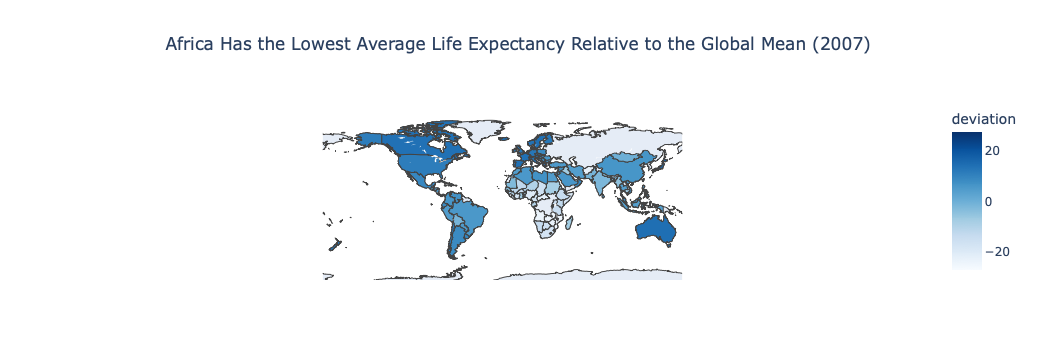

In [6]:
limit = gm_2007['deviation'].abs().max()

fig = px.choropleth(
    gm_2007,
    locations='country',
    locationmode='country names',
    color='deviation',
    hover_name='country',
    hover_data={
        'country': True,
        'lifeExp': ':.2f',
        'deviation': ':.2f'
    },
    color_continuous_scale='blues',
    range_color=[-limit, limit],
    color_continuous_midpoint=0,
    title=f'{lowest_region} Has the Lowest Average Life Expectancy Relative to the Global Mean (2007)'
)

fig.update_layout(
    title_x=0.5,
    geo=dict(showframe=False, showcoastlines=True)
)

fig.show()


## Task 2 — Find your own GeoJSON

**What to build:** A choropleth using a GeoJSON file you find yourself online.

**Requirements:**
- Find a free GeoJSON file for any geography that interests you (country, region, city)
- Create or find a matching dataset with at least one numeric variable per region
- Build either a `px.choropleth` or `px.choropleth_mapbox` — state your choice and reason in the markdown cell below
- Correctly identify and set `featureidkey` by inspecting the GeoJSON properties
- Choose sequential or diverging scale — state your reason in the markdown cell below
- Insight title naming a geographic finding

**Where to find GeoJSON files:**
- [geojson.xyz](https://geojson.xyz/) — countries, cities, natural features
- [naturalearthdata.com](https://www.naturalearthdata.com/) — global admin boundaries
- [github.com/datasets/geo-countries](https://github.com/datasets/geo-countries) — country polygons
- Search: `[country name] [admin level] GeoJSON github` — most countries have free boundary files on GitHub

> 💡 Before plotting, always inspect your GeoJSON properties first:
> ```python
> print(my_geojson['features'][0]['properties'])
> ```
> The property name that matches your dataframe's location column is what goes in `featureidkey='properties.???'`


### Task 2 — Design decisions

**GeoJSON source:** *(URL or description)*

**Chart type chosen** (`px.choropleth` or `px.choropleth_mapbox`) **and reason:**

*Your answer here*

**Colour scale chosen** (sequential or diverging) **and reason:**

*Your answer here*


In [7]:
from pathlib import Path

geojson_path = Path("data/4_niedrig.geo.json")

if not geojson_path.exists():
    geojson_path = Path("../data/4_niedrig.geo.json")

with open(geojson_path, "r", encoding="utf-8") as file:
    my_geojson = json.load(file)

print("GeoJSON loaded successfully!")

GeoJSON loaded successfully!


In [8]:
print("First feature properties:")

print(my_geojson['features'][0]['properties'])

First feature properties:
{'id': 'DE-BW', 'name': 'Baden-Württemberg', 'type': 'State'}


In [9]:
geo_data = pd.json_normalize(
    [feature['properties'] for feature in my_geojson['features']]
)

print("Available columns:")
print(geo_data.columns.tolist())

print("\nFirst five rows:")
display(geo_data.head())

print("\nNumeric columns:")
print(geo_data.select_dtypes(include='number').columns.tolist())

Available columns:
['id', 'name', 'type']

First five rows:


,id,name,type
0,DE-BW,Baden-Württemberg,State
1,DE-BY,Bayern,State
2,DE-BE,Berlin,State
3,DE-BB,Brandenburg,State
4,DE-HB,Bremen,State



Numeric columns:
[]


In [11]:
print("Available columns in your GeoJSON:")

print(geo_data.columns.tolist())

print("\nFirst five rows:")

display(geo_data.head())

print("\nNumeric columns:")

print(geo_data.select_dtypes(include='number').columns.tolist())

Available columns in your GeoJSON:
['id', 'name', 'type', 'region']

First five rows:


,id,name,type,region
0,DE-BW,Baden-Württemberg,State,Baden-Württemberg
1,DE-BY,Bayern,State,Bayern
2,DE-BE,Berlin,State,Berlin
3,DE-BB,Brandenburg,State,Brandenburg
4,DE-HB,Bremen,State,Bremen



Numeric columns:
[]


In [12]:
print("First region:")
print(my_geojson['features'][0]['properties'])

print("\nSecond region:")
print(my_geojson['features'][1]['properties'])

First region:
{'id': 'DE-BW', 'name': 'Baden-Württemberg', 'type': 'State'}

Second region:
{'id': 'DE-BY', 'name': 'Bayern', 'type': 'State'}


In [14]:
fig = px.choropleth(
    geo_data,
    geojson=my_geojson,
    locations='region',
    featureidkey=f'properties.{region_property}',
    color='value',
    color_continuous_scale='Blues',
    hover_name='region',
    hover_data={
        'value': ':.2f'
    },
    title='Geographical Distribution of the Selected Variable'
)

fig.update_geos(
    fitbounds='locations',
    visible=False
)

fig.update_layout(
    title_x=0.5
)

fig.show()

ValueError: Value of 'hover_data_0' is not the name of a column in 'data_frame'. Expected one of ['id', 'name', 'type', 'region'] but received: value

In [15]:
print("All available columns:")
print(geo_data.columns.tolist())

print("\nFirst 10 rows:")
display(geo_data.head(10))

print("\nData types:")
print(geo_data.dtypes)

print("\nGeoJSON properties:")
print(my_geojson['features'][0]['properties'])


All available columns:
['id', 'name', 'type', 'region']

First 10 rows:


,id,name,type,region
0,DE-BW,Baden-Württemberg,State,Baden-Württemberg
1,DE-BY,Bayern,State,Bayern
2,DE-BE,Berlin,State,Berlin
3,DE-BB,Brandenburg,State,Brandenburg
4,DE-HB,Bremen,State,Bremen
5,DE-HH,Hamburg,State,Hamburg
6,DE-HE,Hessen,State,Hessen
7,DE-MV,Mecklenburg-Vorpommern,State,Mecklenburg-Vorpommern
8,DE-NI,Niedersachsen,State,Niedersachsen
9,DE-NW,Nordrhein-Westfalen,State,Nordrhein-Westfalen



Data types:
id        str
name      str
type      str
region    str
dtype: object

GeoJSON properties:
{'id': 'DE-BW', 'name': 'Baden-Württemberg', 'type': 'State'}


In [16]:
print(geo_data.describe(include='all'))

           id               name   type             region
count      16                 16     16                 16
unique     16                 16      1                 16
top     DE-BW  Baden-Württemberg  State  Baden-Württemberg
freq        1                  1     16                  1


In [18]:
from pathlib import Path

current_folder = Path.cwd()

print("Current notebook location:")
print(current_folder)

print("\nFiles in current folder:")
for file in current_folder.iterdir():
    print(file.name)

print("\nChecking data folders:")

possible_folders = [
    current_folder / "data",
    current_folder.parent / "data"
]

for folder in possible_folders:
    if folder.exists():
        print(f"\nFound: {folder}")
        for file in folder.iterdir():
            print(file.name)

Current notebook location:
/Users/divyabharathi/data-viz-class-material-w2026/week06

Files in current folder:
.ipynb_checkpoints
lecture06_exercise.ipynb

Checking data folders:

Found: /Users/divyabharathi/data-viz-class-material-w2026/data
.DS_Store
africa.json
global_energy_mix.csv
netflix_catalogue.csv
co2_emissions.csv
world_development.csv
airbnb_london.csv
berlin_bezirke.geojson
4_niedrig.geo.json
world_happiness_2023.csv
gapminder.csv


In [19]:
from pathlib import Path
import json

geojson_path = Path("../data/berlin_bezirke.geojson")

with open(geojson_path, "r", encoding="utf-8") as file:
    berlin_geojson = json.load(file)

print("Number of Berlin districts:",
      len(berlin_geojson["features"]))

print("\nFirst district properties:")
print(berlin_geojson["features"][0]["properties"])

Number of Berlin districts: 12

First district properties:
{'name': 'Mitte', 'description': '', 'cartodb_id': 1, 'created_at': '2013-09-03T12:32:04+0200', 'updated_at': '2013-09-03T12:32:04+0200'}


In [20]:
import pandas as pd
from pathlib import Path

data_folder = Path("../data")

for file in data_folder.glob("*.csv"):
    df = pd.read_csv(file)
    print("\nFILE:", file.name)
    print("Columns:", df.columns.tolist())
    print("Shape:", df.shape)


FILE: global_energy_mix.csv
Columns: ['Country', 'Region', 'Source', 'Share_pct', 'TWh']
Shape: (103, 5)

FILE: netflix_catalogue.csv
Columns: ['type', 'release_year', 'added_year', 'genre', 'country', 'rating', 'duration']
Shape: (3000, 7)

FILE: co2_emissions.csv
Columns: ['Country', 'Region', 'Year', 'CO2_Mt', 'CO2_per_capita']
Shape: (345, 5)

FILE: world_development.csv
Columns: ['Country', 'Region', 'HDI', 'Life_Expectancy', 'GNI_per_capita', 'Fertility_Rate', 'Population_M', 'Urban_pct']
Shape: (20, 8)

FILE: airbnb_london.csv
Columns: ['neighbourhood', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'availability_365', 'reviews_per_month']
Shape: (2500, 7)

FILE: world_happiness_2023.csv
Columns: ['Country name', 'Regional indicator', 'Ladder score', 'Logged GDP per capita', 'Social support', 'Healthy life expectancy', 'Freedom to make life choices', 'Generosity', 'Perceptions of corruption']
Shape: (63, 9)

FILE: gapminder.csv
Columns: ['Country', 'Continent', 'G

In [21]:
africa_path = Path("../data/africa.json")

with open(africa_path, "r", encoding="utf-8") as file:
    africa_geojson = json.load(file)

print("Number of geographical features:",
      len(africa_geojson["features"]))

print("\nFirst feature properties:")
print(africa_geojson["features"][0]["properties"])

Number of geographical features: 51

First feature properties:
{'featurecla': 'Admin-0 country', 'scalerank': 1, 'labelrank': 2, 'sovereignt': 'Ethiopia', 'sov_a3': 'ETH', 'adm0_dif': 0, 'level': 2, 'type': 'Sovereign country', 'tlc': '1', 'admin': 'Ethiopia', 'adm0_a3': 'ETH', 'geou_dif': 0, 'geounit': 'Ethiopia', 'gu_a3': 'ETH', 'su_dif': 0, 'subunit': 'Ethiopia', 'su_a3': 'ETH', 'brk_diff': 0, 'name': 'Ethiopia', 'name_long': 'Ethiopia', 'brk_a3': 'ETH', 'brk_name': 'Ethiopia', 'brk_group': None, 'abbrev': 'Eth.', 'postal': 'ET', 'formal_en': 'Federal Democratic Republic of Ethiopia', 'formal_fr': None, 'name_ciawf': 'Ethiopia', 'note_adm0': None, 'note_brk': None, 'name_sort': 'Ethiopia', 'name_alt': None, 'mapcolor7': 4, 'mapcolor8': 4, 'mapcolor9': 1, 'mapcolor13': 13, 'pop_est': 112078730, 'pop_rank': 17, 'pop_year': 2019, 'gdp_md': 95912, 'gdp_year': 2019, 'economy': '7. Least developed region', 'income_grp': '5. Low income', 'fips_10': 'ET', 'iso_a2': 'ET', 'iso_a2_eh': 'ET', 

In [22]:
energy = pd.read_csv("../data/global_energy_mix.csv")

print(energy.head(10))

print("\nAvailable countries:")
print(sorted(energy["Country"].unique()))

         Country         Region            Source  Share_pct     TWh
0  United States  North America              Coal         10  1015.0
1  United States  North America               Oil         35  3220.0
2  United States  North America       Natural Gas         34  3083.0
3  United States  North America           Nuclear          9   798.0
4  United States  North America             Hydro          3   339.0
5  United States  North America              Wind          4   413.0
6  United States  North America             Solar          3   325.0
7  United States  North America  Other Renewables          2   229.0
8          China           Asia              Coal         58  6929.1
9          China           Asia               Oil         18  1620.0

Available countries:
['Australia', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'India', 'Japan', 'Mexico', 'Norway', 'Saudi Arabia', 'South Africa', 'South Korea', 'United Kingdom', 'United States']


In [23]:
import pandas as pd
import plotly.express as px
import json

africa_data = pd.json_normalize(
    [feature['properties'] for feature in africa_geojson['features']]
)

africa_data = africa_data[['name', 'pop_est']].copy()

africa_data = africa_data.rename(columns={
    'name': 'country',
    'pop_est': 'population'
})

africa_data['population'] = pd.to_numeric(
    africa_data['population'],
    errors='coerce'
)

africa_data.head()

,country,population
0,Ethiopia,112078730.0
1,S. Sudan,11062113.0
2,Somalia,10192317.3
3,Kenya,52573973.0
4,Malawi,18628747.0


In [24]:
top_countries = africa_data.sort_values(
    'population',
    ascending=False
)

print("Five most populated African countries:")

display(top_countries.head(5))

Five most populated African countries:


,country,population
26,Nigeria,200963599.0
0,Ethiopia,112078730.0
46,Egypt,100388073.0
10,Dem. Rep. Congo,86790567.0
12,South Africa,58558270.0


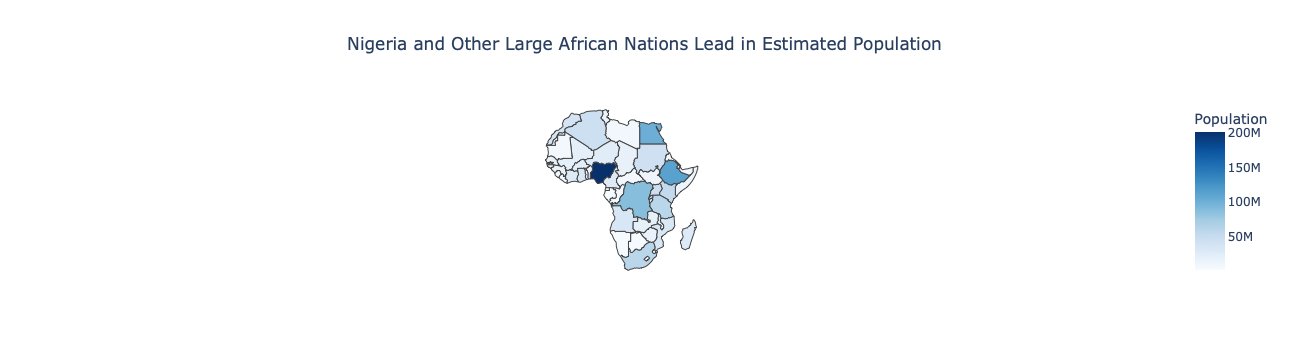

In [25]:
fig = px.choropleth(
    africa_data,
    geojson=africa_geojson,
    locations='country',
    featureidkey='properties.name',
    color='population',
    hover_name='country',
    hover_data={
        'population': ':,.0f'
    },
    color_continuous_scale='Blues',
    title='Nigeria and Other Large African Nations Lead in Estimated Population'
)

fig.update_geos(
    fitbounds='locations',
    visible=False
)

fig.update_layout(
    title_x=0.5,
    coloraxis_colorbar_title='Population'
)

fig.show()

### Task 2 — Design decisions

**GeoJSON source:** `africa.json` (Natural Earth country boundaries).

**Chart type chosen:** `px.choropleth`.

**Reason:** It allows us to display population values across African countries using their geographical boundaries. It does not require a Mapbox token.

**Feature ID key:** `properties.name`, matching the country names in the dataframe.

**Colour scale chosen:** Sequential (`Blues`).

**Reason:** Population is a numerical variable where higher values represent larger populations. A sequential colour scale makes it easy to compare population sizes across countries.

**Geographic finding:** Countries such as Nigeria have much larger estimated populations than many other African countries.